# ANÁLISE DE MORTALIDADE MATERNA E INFANTIL

Abaixo estão os gráficos que possibilitam a analisar as relações entre os fatores que podem ou não contribuir para o aumento da probabilidade de falecimento nos casos que envolvem bebês, crianças e mães em relação a gravidez,  parto e determinados fatores socieconômicos e demográficos.

## Mortalidade Infantil
1. Análise de Distribuição e Dispersão:
    * Idade;
    * Peso;
2. Fatores do Parto e Gravidez:
    * Óbitos em Parto;
    * Idade;
    * Gravidez e Tipo de Óbito;
    * Gravidez e Tipo de Parto Realizado;
    * 
3. Perfil Socioeconômico e Demográfico:
    * Idade da Mãe;
    * Escolaridade da Mãe;
    * Ocupação da Mãe;
4. Período e Circunstâncias do Óbito:
    * Relação entre o Tipo de Óbito e a Assistência Médica Prestada;

## Mortalidade Materna


In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

columns = [
    'TIPOBITO', 'IDADEMAE', 'ESCMAE2010', 'GRAVIDEZ', 'PARTO', 'OBITOPARTO','PESO','IDADE','OCUPMAE','QTDFILMORT',
    'QTDFILVIVO', 'LOCOCOR','ASSISTMED','GESTACAO','SEXO','OBITOPUERP','OBITOGRAV', 'CAUSABAS', 'SEMAGESTAC', 'TPMORTEOCO',
    'MORTEPARTO', 'IDADE_ANOS','CODMUNRES'
    ]

df = pd.read_csv('../../data/processed/sim_sc_processado_analitico.csv')
df = df[columns]
df = df[df['CODMUNRES'].astype(str).isin(['420140', '4201406'])]

C:\Users\mirel\AppData\Local\Temp\ipykernel_15244\2763931466.py:11: DtypeWarning: Columns (0: DTOBITO, 1: DTNASC, 2: RACACOR, 3: ESC, 4: OCUP, 5: IDADEMAE, 6: ESCMAE, 7: QTDFILVIVO, 8: QTDFILMORT, 9: GESTACAO, 10: CAUSAMAT, 11: LINHAA, 12: LINHAB, 13: LINHAC, 14: LINHAD, 15: LINHAII) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../../data/processed/sim_sc_processado_analitico.csv')


In [49]:
mapa_tipobito = {
    1: "Óbito Fetal",
    2: "Óbito Não Fetal",
    "1": "Óbito Fetal",
    "2": "Óbito Não Fetal"
}

mapa_gravidez = {
    1: "Única",
    2: "Dupla (Gêmeos)",
    3: "Tripla ou mais",
    9: "Ignorado",
    "1": "Única",
    "2": "Dupla (Gêmeos)",
    "3": "Tripla ou mais",
    "9": "Ignorado"
}

mapa_parto = {
    1: "Vaginal (Normal)",
    2: "Cesáreo",
    9: "Ignorado",
    "1": "Vaginal (Normal)",
    "2": "Cesáreo",
    "9": "Ignorado"
}

mapa_obitoparto = {
    1: "Antes do Parto",
    2: "Durante o Parto",
    3: "Depois do Parto",
    9: "Ignorado",
    "1": "Antes do Parto",
    "2": "Durante o Parto",
    "3": "Depois do Parto",
    "9": "Ignorado"
}

mapa_gestacao = {
    1: "Menos de 22 semanas",
    2: "22 a 27 semanas",
    3: "28 a 31 semanas",
    4: "32 a 36 semanas",
    5: "37 a 41 semanas",
    6: "42 semanas e mais",
    9: "Ignorado",
    "1": "Menos de 22 semanas",
    "2": "22 a 27 semanas",
    "3": "28 a 31 semanas",
    "4": "32 a 36 semanas",
    "5": "37 a 41 semanas",
    "6": "42 semanas e mais",
    "9": "Ignorado"
}

mapa_obitopuerp = {
    1: "Sim, até 42 dias",
    2: "Sim, de 43 dias a 1 ano",
    3: "Não",
    9: "Ignorado",
    "1": "Sim, até 42 dias",
    "2": "Sim, de 43 dias a 1 ano",
    "3": "Não",
    "9": "Ignorado"
}

mapa_obitograv = {
    1: "Sim",
    2: "Não",
    9: "Ignorado",
    "1": "Sim",
    "2": "Não",
    "9": "Ignorado"
}

mapa_tpmorteoco = {
    1: "Na gravidez",
    2: "No parto",
    3: "No abortamento",
    4: "Até 42 dias após o parto",
    5: "De 43 dias a 1 ano após o parto",
    8: "Não ocorreu nesses períodos",
    9: "Ignorado",
    "1": "Na gravidez",
    "2": "No parto",
    "3": "No abortamento",
    "4": "Até 42 dias após o parto",
    "5": "De 43 dias a 1 ano após o parto",
    "8": "Não ocorreu nesses períodos",
    "9": "Ignorado"
}


In [50]:
mapeamentos = {
    "TIPOBITO": mapa_tipobito,
    "GRAVIDEZ": mapa_gravidez,
    "PARTO": mapa_parto,
    "OBITOPARTO": mapa_obitoparto,
    "GESTACAO": mapa_gestacao,
    "OBITOPUERP": mapa_obitopuerp,
    "OBITOGRAV": mapa_obitograv,
    "TPMORTEOCO": mapa_tpmorteoco,
}

# 2. Substituição segura que mantém os dados reais
for col, mapa in mapeamentos.items():
    if col in df.columns:
        # Padroniza para texto sem '.0' ou espaços extras
        s = df[col].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
        
        # O .replace() troca o que encontra no mapa e MANTÉM o valor original se não achar
        df[col] = s.replace(mapa)

# 3. Trata colunas puramente numéricas
if "SEMAGESTAC" in df.columns:
    df["SEMAGESTAC"] = pd.to_numeric(df["SEMAGESTAC"], errors="coerce")

if "PESO" in df.columns:
    df["PESO"] = pd.to_numeric(df["PESO"], errors="coerce")


### OBITOS INFANTIS

In [51]:
df_infantil = df[df['IDADE_ANOS'] < 10]
df_infantil.info()
print("Quantidade de óbitos: ", len(df_infantil))
print("Quantidade de óbitos fetais: ", len(df[df['TIPOBITO'] == 1]))

<class 'pandas.DataFrame'>
Index: 1111 entries, 4381 to 1501324
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   TIPOBITO    1111 non-null   str    
 1   IDADEMAE    790 non-null    object 
 2   ESCMAE2010  120 non-null    float64
 3   GRAVIDEZ    808 non-null    str    
 4   PARTO       812 non-null    str    
 5   OBITOPARTO  208 non-null    str    
 6   PESO        867 non-null    float64
 7   IDADE       1111 non-null   float64
 8   OCUPMAE     790 non-null    float64
 9   QTDFILMORT  711 non-null    object 
 10  QTDFILVIVO  857 non-null    object 
 11  LOCOCOR     1109 non-null   str    
 12  ASSISTMED   945 non-null    float64
 13  GESTACAO    240 non-null    str    
 14  SEXO        1111 non-null   str    
 15  OBITOPUERP  10 non-null     str    
 16  OBITOGRAV   10 non-null     str    
 17  CAUSABAS    1111 non-null   str    
 18  SEMAGESTAC  671 non-null    float64
 19  TPMORTEOCO  10 non-null     str    
 

OBITOS INFANTIS: PREMATURIDADE E EXTREMOS

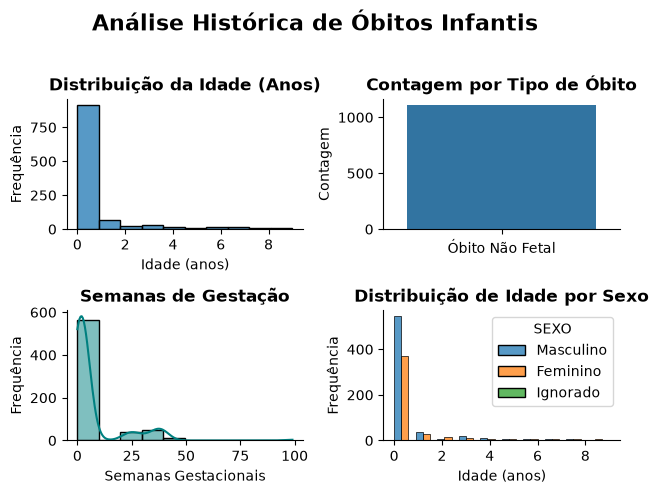

In [52]:
fig = plt.figure()
ax1 = fig.add_subplot(2,2,1)
ax2 = fig.add_subplot(2,2,2)
ax3 = fig.add_subplot(2,2,3)
ax4 = fig.add_subplot(2,2,4)


sns.histplot(data=df_infantil["IDADE_ANOS"], bins=10, ax=ax1)
ax1.set_title("Distribuição da Idade (Anos)", fontweight="bold")
ax1.set_xlabel("Idade (anos)")
ax1.set_ylabel("Frequência")

sns.countplot(data=df_infantil, ax= ax2, x="TIPOBITO")
ax2.set_title("Contagem por Tipo de Óbito", fontweight="bold")
ax2.set_xlabel("")
ax2.set_ylabel("Contagem")

sns.histplot(data=df_infantil.dropna(subset=['SEMAGESTAC']), x='SEMAGESTAC', bins=10, ax=ax3, kde=True, color="teal")
ax3.set_title("Semanas de Gestação", fontweight="bold")
ax3.set_xlabel("Semanas Gestacionais")
ax3.set_ylabel("Frequência")

sns.histplot(data=df_infantil, x="IDADE_ANOS", hue="SEXO", ax=ax4, multiple="dodge", bins=10)
ax4.set_title("Distribuição de Idade por Sexo", fontweight="bold")
ax4.set_xlabel("Idade (anos)")
ax4.set_ylabel("Frequência")

sns.despine()
plt.suptitle("Análise Histórica de Óbitos Infantis", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


OBITOS INFANTIS: CONDICOES DE PARTO E GRAVIDEZ

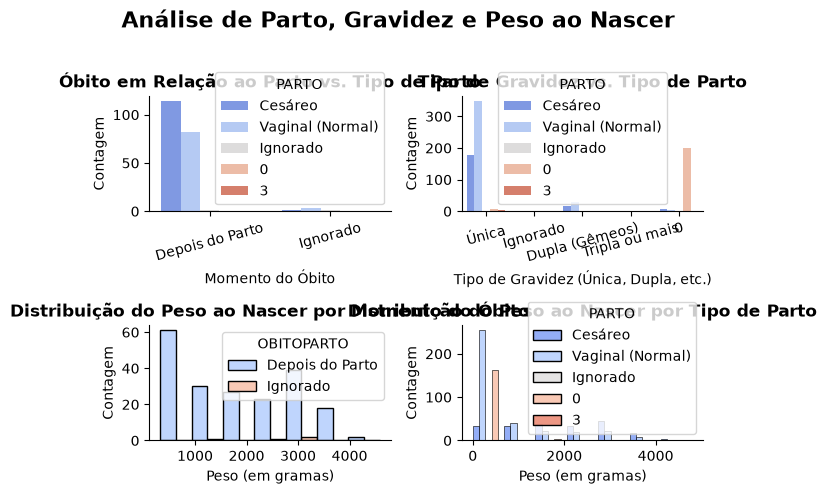

In [53]:
fig = plt.figure()
ax1 = fig.add_subplot(2,2,1)
ax2 = fig.add_subplot(2,2,2)
ax3 = fig.add_subplot(2,2,3)
ax4 = fig.add_subplot(2,2,4)

sns.countplot(data=df_infantil, x='OBITOPARTO', hue='PARTO', ax=ax1, palette="coolwarm")
ax1.set_title("Óbito em Relação ao Parto vs. Tipo de Parto", fontweight="bold")
ax1.set_xlabel("Momento do Óbito")
ax1.set_ylabel("Contagem")
ax1.tick_params(axis="x", rotation=15)

sns.countplot(data=df_infantil, x='GRAVIDEZ', hue='PARTO', ax=ax2, palette="coolwarm")
ax2.set_title("Tipo de Gravidez vs. Tipo de Parto", fontweight="bold")
ax2.set_xlabel("Tipo de Gravidez (Única, Dupla, etc.)")
ax2.set_ylabel("Contagem")
ax2.tick_params(axis="x", rotation=15)

sns.histplot(data=df_infantil, x='PESO', bins=7, ax=ax3, hue='OBITOPARTO', palette="coolwarm", multiple="dodge")
ax3.set_title("Distribuição do Peso ao Nascer por Momento do Óbito", fontweight="bold")
ax3.set_xlabel("Peso (em gramas)")
ax3.set_ylabel("Contagem")

sns.histplot(data=df_infantil, x='PESO', bins=7, ax=ax4, hue='PARTO', palette="coolwarm", multiple="dodge")
ax4.set_title("Distribuição do Peso ao Nascer por Tipo de Parto", fontweight="bold")
ax4.set_xlabel("Peso (em gramas)")
ax4.set_ylabel("Contagem")

sns.despine()
plt.suptitle("Análise de Parto, Gravidez e Peso ao Nascer", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


C:\Users\mirel\AppData\Local\Temp\ipykernel_15244\2489556593.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_infantil, x="OBITOPARTO", ax=ax2, legend=False, palette="mako")
C:\Users\mirel\AppData\Local\Temp\ipykernel_15244\2489556593.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_infantil, x="GRAVIDEZ", y="GESTACAO", ax=ax3, palette="mako")
C:\Users\mirel\AppData\Local\Temp\ipykernel_15244\2489556593.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_infantil["GESTACAO"], palette="mako") # , hue="CAUS

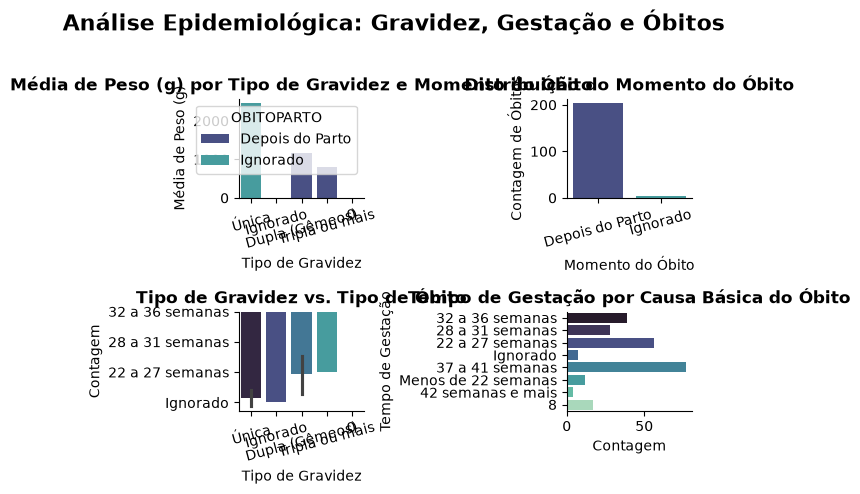

In [54]:
fig = plt.figure()
ax1 = fig.add_subplot(2,2,1)
ax2 = fig.add_subplot(2,2,2)
ax3 = fig.add_subplot(2,2,3)
ax4 = fig.add_subplot(2,2,4)

sns.barplot(data=df_infantil, x="GRAVIDEZ", y="PESO", hue="OBITOPARTO", ax=ax1, palette="mako",errorbar=None)
ax1.set_title("Média de Peso (g) por Tipo de Gravidez e Momento do Óbito", fontweight="bold")
ax1.set_xlabel("Tipo de Gravidez")
ax1.set_ylabel("Média de Peso (g)")
ax1.tick_params(axis="x", rotation=15)

sns.countplot(data=df_infantil, x="OBITOPARTO", ax=ax2, legend=False, palette="mako")
ax2.set_title("Distribuição do Momento do Óbito", fontweight="bold")
ax2.set_xlabel("Momento do Óbito")
ax2.set_ylabel("Contagem de Óbitos")
ax2.tick_params(axis="x", rotation=15)

sns.barplot(data=df_infantil, x="GRAVIDEZ", y="GESTACAO", ax=ax3, palette="mako")
ax3.set_title("Tipo de Gravidez vs. Tipo de Óbito", fontweight="bold")
ax3.set_xlabel("Tipo de Gravidez")
ax3.set_ylabel("Contagem")
ax3.tick_params(axis="x", rotation=15)

sns.countplot(data=df_infantil["GESTACAO"], palette="mako") # , hue="CAUSABAS" ou gravidez
ax4.set_title("Tempo de Gestação por Causa Básica do Óbito", fontweight="bold")
ax4.set_xlabel("Contagem")
ax4.set_ylabel("Tempo de Gestação")

sns.despine()
plt.suptitle("Análise Epidemiológica: Gravidez, Gestação e Óbitos", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

OBITOS INFANTIS: PERFIL SOCIOECONOMICO E DEMOGRAFICO

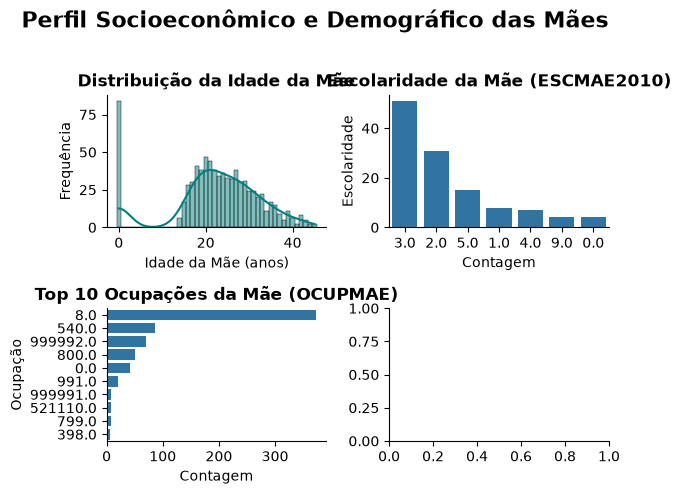

In [55]:
fig = plt.figure()
ax1 = fig.add_subplot(2,2,1)
ax2 = fig.add_subplot(2,2,2)
ax3 = fig.add_subplot(2,2,3)
ax4 = fig.add_subplot(2,2,4)

sns.histplot(data=df_infantil, x="IDADEMAE",bins=15, kde=True, ax=ax1, color="teal")
ax1.set_title("Distribuição da Idade da Mãe", fontweight="bold")
ax1.set_xlabel("Idade da Mãe (anos)")
ax1.set_ylabel("Frequência")

sns.countplot(data=df_infantil, x="ESCMAE2010", ax=ax2, order=df_infantil["ESCMAE2010"].value_counts().index)
ax2.set_title("Escolaridade da Mãe (ESCMAE2010)", fontweight="bold")
ax2.set_xlabel("Contagem")
ax2.set_ylabel("Escolaridade")

top_ocupacoes = df_infantil["OCUPMAE"].value_counts().nlargest(10).index
sns.countplot(data=df_infantil[df_infantil["OCUPMAE"].isin(top_ocupacoes)], y="OCUPMAE", ax=ax3, order=top_ocupacoes)
ax3.set_title("Top 10 Ocupações da Mãe (OCUPMAE)", fontweight="bold")
ax3.set_xlabel("Contagem")
ax3.set_ylabel("Ocupação")

sns.despine()
plt.suptitle("Perfil Socioeconômico e Demográfico das Mães", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

OBITOS INFANTIS: PERIODO E CIRCUNSTANCIAS

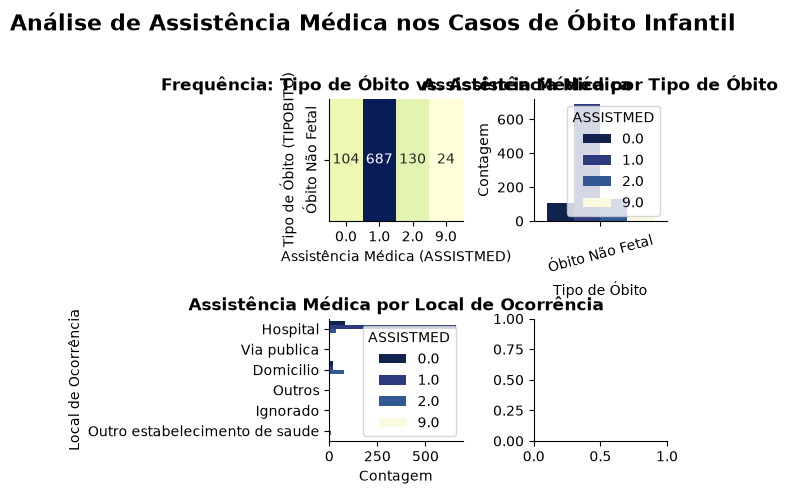

In [56]:
fig = plt.figure()
ax1 = fig.add_subplot(2,2,1)
ax2 = fig.add_subplot(2,2,2)
ax3 = fig.add_subplot(2,2,3)
ax4 = fig.add_subplot(2,2,4)

crosstab_assist = pd.crosstab(df_infantil["TIPOBITO"], df_infantil["ASSISTMED"])
sns.heatmap(crosstab_assist, annot=True, fmt="d", cmap="YlGnBu", ax=ax1, cbar=False)
ax1.set_title("Frequência: Tipo de Óbito vs. Assistência Médica", fontweight="bold")
ax1.set_xlabel("Assistência Médica (ASSISTMED)")
ax1.set_ylabel("Tipo de Óbito (TIPOBITO)")

sns.countplot(data=df_infantil, x="TIPOBITO", hue="ASSISTMED",  ax=ax2, palette="YlGnBu_r")
ax2.set_title("Assistência Médica por Tipo de Óbito", fontweight="bold")
ax2.set_xlabel("Tipo de Óbito")
ax2.set_ylabel("Contagem")
ax2.tick_params(axis="x", rotation=15)

sns.countplot(data=df_infantil, y="LOCOCOR", hue="ASSISTMED", ax=ax3, palette="YlGnBu_r")
ax3.set_title("Assistência Médica por Local de Ocorrência", fontweight="bold")
ax3.set_xlabel("Contagem")
ax3.set_ylabel("Local de Ocorrência")

sns.despine()
plt.suptitle("Análise de Assistência Médica nos Casos de Óbito Infantil", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### OBITOS MATERNOS

In [57]:
df_materno = df[df['SEXO'] == 'Feminino']
df_materno= df_materno[(df_materno['OBITOGRAV'] == 1) | (df_materno['OBITOPUERP'] == 1) | (df_materno['OBITOPUERP'] == 2)]
df_materno.info()
print("Quantidade de óbitos: ", len(df_materno))

<class 'pandas.DataFrame'>
Index: 0 entries
Data columns (total 23 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   TIPOBITO    0 non-null      str    
 1   IDADEMAE    0 non-null      object 
 2   ESCMAE2010  0 non-null      float64
 3   GRAVIDEZ    0 non-null      str    
 4   PARTO       0 non-null      str    
 5   OBITOPARTO  0 non-null      str    
 6   PESO        0 non-null      float64
 7   IDADE       0 non-null      float64
 8   OCUPMAE     0 non-null      float64
 9   QTDFILMORT  0 non-null      object 
 10  QTDFILVIVO  0 non-null      object 
 11  LOCOCOR     0 non-null      str    
 12  ASSISTMED   0 non-null      float64
 13  GESTACAO    0 non-null      str    
 14  SEXO        0 non-null      str    
 15  OBITOPUERP  0 non-null      str    
 16  OBITOGRAV   0 non-null      str    
 17  CAUSABAS    0 non-null      str    
 18  SEMAGESTAC  0 non-null      float64
 19  TPMORTEOCO  0 non-null      str    
 20  MORTEPARTO  0 no